# 01 — Data Collection and Storage

**Goal:** demonstrate how FinRisk pulls raw market data through the
`DataProvider` abstraction (`src/data/ingestion.py`) and persists it,
untouched, to the `raw_market_prices` table.

**Disclaimer:** educational/analytical use only, not investment advice.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["figure.figsize"] = (10, 5)

np.random.seed(42)

from notebooks.nb_utils import fetch_price_panel

TICKERS = ["AAPL", "MSFT", "GLD", "BND", "SPY"]
START = "2019-01-01"

price_panel, used_synthetic = fetch_price_panel(TICKERS, START)
returns_panel = price_panel.pct_change().dropna()
print(f"Loaded {price_panel.shape[0]} rows x {price_panel.shape[1]} tickers. Synthetic data: {used_synthetic}")
price_panel.tail()

Failed to get ticker 'AAPL' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


Failed to get ticker 'BND' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


... (7 outputs left out)

['AAPL', 'BND']: JSONDecodeError('Expecting value: line 1 column 1 (char 0)')


['SPY', 'MSFT', 'GLD']: possibly delisted; no timezone found


[info] Live data unavailable (KeyError); using synthetic demo data instead.
Loaded 2004 rows x 5 tickers. Synthetic data: True


,AAPL,MSFT,GLD,BND,SPY
2026-08-31,229.681016,128.274867,119.914845,364.746718,107.728124
2026-09-01,227.093540,128.294744,120.000708,372.445526,106.711406
2026-09-02,229.155329,127.875189,121.085078,365.765614,106.991434
2026-09-03,232.958620,125.652809,122.697759,374.610608,107.656847
2026-09-04,232.705684,125.622649,120.900524,369.667262,106.661264


## Why a `DataProvider` abstraction?

`MarketDataProvider` wraps `yfinance` behind a small interface so the rest of the codebase never imports `yfinance` directly — swapping data vendors later means writing one new class, not touching validation/cleaning/features/models.

In [2]:
from src.data.ingestion import MarketDataProvider

provider = MarketDataProvider()
print(provider.SOURCE_NAME)
print(provider.fetch.__doc__)

yfinance
None


## Raw data summary

This is what actually came back from the provider (or the synthetic fallback), before any cleaning.

In [3]:
summary = price_panel.describe().T
summary["missing_days"] = price_panel.isna().sum()
summary

,count,mean,std,min,25%,50%,75%,max,missing_days
AAPL,2004.0,186.155851,40.613817,100.610529,149.460016,198.213650,217.957894,258.185030,0
MSFT,2004.0,118.639685,25.730630,69.885854,94.209231,119.994074,143.410403,166.169227,0
GLD,2004.0,123.817128,31.863999,68.525685,93.133890,123.179733,148.080153,203.560879,0
BND,2004.0,184.396138,68.556776,99.593544,126.384175,162.985826,223.666756,375.763835,0
SPY,2004.0,102.312019,10.490346,82.101203,95.453517,100.431745,109.003663,135.568549,0


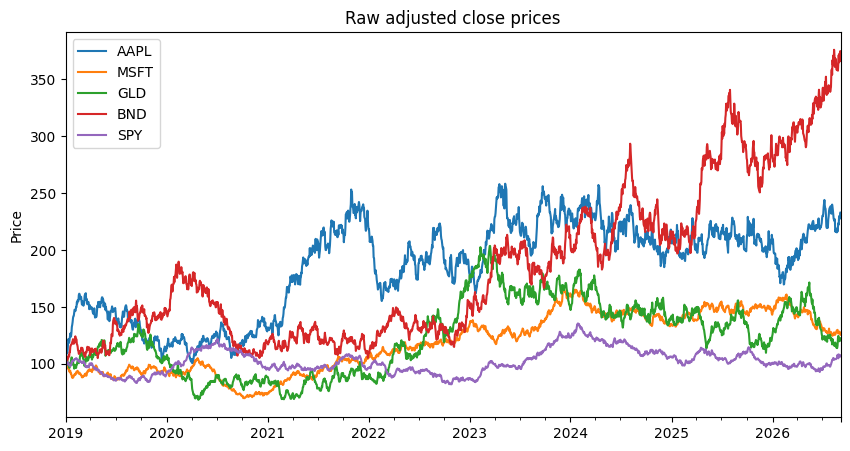

In [4]:
price_panel.plot(title="Raw adjusted close prices")
plt.ylabel("Price")
plt.show()

## Persisting to MySQL (`raw_market_prices`)

In a full run with a MySQL instance available, this is done via:

```python
from src.data.ingestion import ingest
ingest(TICKERS, START)
```

which writes to `assets` and `raw_market_prices` through `src/data/repository.py`, using `INSERT ... ON DUPLICATE KEY UPDATE` so raw rows are never overwritten once inserted (see `database/schema.sql` and README §6).

## Takeaways

- Raw data is kept completely separate from cleaned data (`clean_market_prices`), so a bug in cleaning can always be diagnosed against the untouched source.
- The `DataProvider` interface means adding a new vendor (e.g. a paid data feed) requires no changes outside `src/data/ingestion.py`.
- Continue to **02 — Data Cleaning and Validation** to see how raw data becomes trustworthy analysis-ready data.